# Lab 11-04 · LTI Systems and Differential/Difference Equations

Companion to [chapter 11-04](../../chapters/11-04-lti-systems-and-differential-equations.md). Four parts: iterating difference equations, an RLC circuit driven by narrowing pulses, filter structures and coefficient rounding, and eigenfunctions. Run the cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import solve_ivp

## Part 1 — Iterating difference equations

Run the recipe from rest with a unit-sample input and compare with the closed forms of §3.2. Then move a pair of complex roots outward and watch the response change character.

real roots: max |iteration - closed form| = 1.9984014443252818e-15
r = 0.9: largest |h[n]| for n = 32..39: 0.044
r = 1.0: largest |h[n]| for n = 32..39: 1.414
r = 1.02: largest |h[n]| for n = 32..39: 2.943


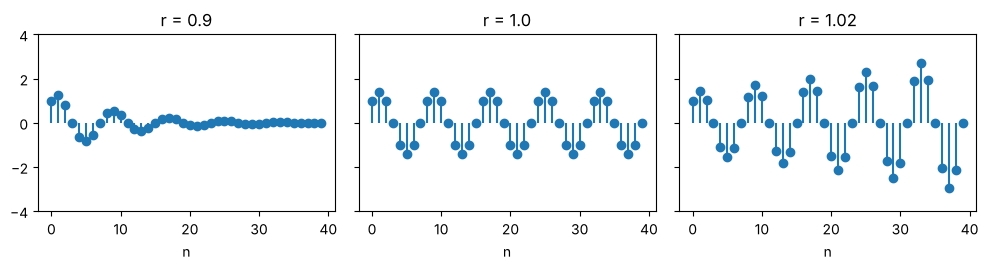

In [2]:
def iterate(b, a, x):
    """y[n] = sum b_k x[n-k] - sum_{k>=1} a_k y[n-k], with a[0] = 1, from rest."""
    y = np.zeros(len(x))
    for n in range(len(x)):
        acc = sum(b[k] * x[n - k] for k in range(len(b)) if n - k >= 0)
        acc -= sum(a[k] * y[n - k] for k in range(1, len(a)) if n - k >= 0)
        y[n] = acc
    return y

d = np.zeros(40); d[0] = 1
h3 = iterate([1], [1, -1.5, 0.56], d)
closed = (0.8 ** (np.arange(40) + 1) - 0.7 ** (np.arange(40) + 1)) / 0.1
print("real roots: max |iteration - closed form| =", np.max(np.abs(h3 - closed)))

fig, axs = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, r in zip(axs, (0.9, 1.0, 1.02)):
    c = 2 * r * np.cos(np.pi / 4)
    h = iterate([1], [1, -c, r * r], d)
    ax.stem(h, basefmt=" "); ax.set_title(f"r = {r}"); ax.set_xlabel("n")
    print(f"r = {r}: largest |h[n]| for n = 32..39: {np.max(np.abs(h[32:40])):.3f}")
axs[0].set_ylim(-4, 4); plt.tight_layout(); plt.show()

## Part 2 — Approaching the impulse response of an RLC circuit

Drive the circuit of Example 11-04.5 with unit-area pulses of shrinking width and compare with $h(t)$. Watch the slope at $t = 0^+$ approach $\omega_0^2$ while the voltage stays continuous.

pulse width   20 us: largest difference from h after the pulse =   4299.8 1/s
pulse width    5 us: largest difference from h after the pulse =   2008.4 1/s


pulse width    1 us: largest difference from h after the pulse =    477.6 1/s


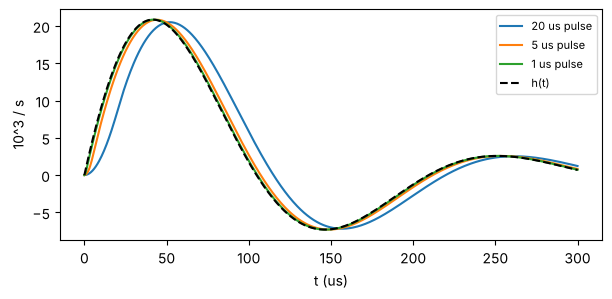

In [3]:
L, C, R = 1e-3, 1e-6, 20.0
w0, a = 1 / np.sqrt(L * C), R / (2 * L)
wd = np.sqrt(w0 ** 2 - a ** 2)
h_exact = lambda t: w0 ** 2 / wd * np.exp(-a * t) * np.sin(wd * t)

def pulse_response(width, t_end=300e-6):
    src = lambda t: (1 / width) if t < width else 0.0
    rhs = lambda t, y: [y[1], w0 ** 2 * (src(t) - y[0]) - 2 * a * y[1]]
    return solve_ivp(rhs, (0, t_end), [0.0, 0.0], max_step=width / 20, rtol=1e-9, atol=1e-6, dense_output=True)

tt = np.linspace(0, 300e-6, 601)
plt.figure(figsize=(7, 3))
for wdt in (20e-6, 5e-6, 1e-6):
    s = pulse_response(wdt)
    err = np.max(np.abs(s.sol(tt[tt > 2 * wdt])[0] - h_exact(tt[tt > 2 * wdt])))
    print(f"pulse width {wdt * 1e6:4.0f} us: largest difference from h after the pulse = {err:8.1f} 1/s")
    plt.plot(tt * 1e6, s.sol(tt)[0] / 1e3, label=f"{wdt * 1e6:g} us pulse")
plt.plot(tt * 1e6, h_exact(tt) / 1e3, "k--", label="h(t)")
plt.xlabel("t (us)"); plt.ylabel("10^3 / s"); plt.legend(fontsize=8); plt.show()

## Part 3 — Structures and coefficient rounding (guided exercise)

**Predict first:** an eighth-order Butterworth low-pass with cutoff $0.05\pi$ is implemented once as a single direct form and once as four biquads, with every coefficient rounded to 12 fractional bits. Which stays stable? Then run the cell. First, check that three biquad structures give the same output.

In [4]:
b, a = [0.0675, 0.1349, 0.0675], [1.0, -1.143, 0.4128]   # a smooth second-order low-pass section
x = np.random.default_rng(1104).normal(size=200)

def df1(b, a, x):
    return iterate(b, a, x)

def df2(b, a, x):
    w1 = w2 = 0.0; y = np.zeros(len(x))
    for n, xn in enumerate(x):
        w = xn - a[1] * w1 - a[2] * w2
        y[n] = b[0] * w + b[1] * w1 + b[2] * w2
        w2, w1 = w1, w
    return y

def df2t(b, a, x):
    d1 = d2 = 0.0; y = np.zeros(len(x))
    for n, xn in enumerate(x):
        y[n] = b[0] * xn + d1
        d1 = b[1] * xn - a[1] * y[n] + d2
        d2 = b[2] * xn - a[2] * y[n]
    return y

ys = [f(b, a, x) for f in (df1, df2, df2t)]
print("largest disagreement between structures:", max(np.max(np.abs(ys[0] - y)) for y in ys[1:]))

bb, aa = signal.butter(8, 0.05)
q = lambda c: np.round(np.asarray(c) * 2 ** 12) / 2 ** 12
r_orig = np.max(np.abs(np.roots(aa)))
r_direct = np.max(np.abs(np.roots(q(aa))))
sos = signal.tf2sos(bb, aa)
r_sos = max(np.max(np.abs(np.roots(sec[3:]))) for sec in q(sos))
print(f"largest pole radius: designed {r_orig:.4f}; direct form rounded {r_direct:.4f}; biquads rounded {r_sos:.4f}")

largest disagreement between structures: 4.440892098500626e-16
largest pole radius: designed 0.9699; direct form rounded 1.2031; biquads rounded 0.9699


## Part 4 — Eigenfunctions, measured

Drive the filter of Example 11-04.2 with a long cosine and with a one-sided exponential, and measure the steady-state ratio of output to input.

In [5]:
bE, aE = [1, 1], [1, -0.5]
n = np.arange(400)
w = np.pi / 3
H = (1 + np.exp(-1j * w)) / (1 - 0.5 * np.exp(-1j * w))
y = signal.lfilter(bE, aE, np.cos(w * n))
amp = np.max(np.abs(y[300:]))
print(f"cosine at pi/3: measured amplitude {amp:.4f}, |H| = {abs(H):.4f}")

x9 = 0.9 ** n
y9 = signal.lfilter(bE, aE, x9)
print("ratio y/x at n = 2, 10, 40:", [round(y9[k] / x9[k], 4) for k in (2, 10, 40)], "-> H(0.9) = 4.75")

cosine at pi/3: measured amplitude 2.0000, |H| = 2.0000
ratio y/x at n = 2, 10, 40: [np.float64(3.5926), np.float64(4.7395), np.float64(4.75)] -> H(0.9) = 4.75


**What to take away.** A difference equation is a recipe whose impulse response follows from its roots; a differential equation's impulse response is its natural response started by the jump conditions. Structures that compute the same equation exactly can behave very differently once coefficients are rounded, which is why recursive filters are built from biquads. And the eigenfunction property is measurable: once start-up transients fade, the output is the input times $H$.